In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("loan_approval_data (1).csv")

In [3]:
df.shape

(1000, 20)

In [4]:
df.describe()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term
count,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000
mean,501.220000,10852.571579,5082.455789,39.971579,1.474737,676.033684,1.950526,0.347263,9940.452632,24802.792632,20522.825263,48.000000
std,289.608451,5061.632859,2943.161570,11.139797,1.105067,71.346015,1.406246,0.144341,5860.736885,14345.696031,11504.142575,24.245322
min,1.000000,2009.000000,1.000000,21.000000,0.000000,550.000000,0.000000,0.100000,65.000000,36.000000,1015.000000,12.000000
25%,250.250000,6730.750000,2472.750000,30.250000,1.000000,616.250000,1.000000,0.220000,4760.250000,12698.250000,9806.250000,24.000000
50%,499.500000,10548.000000,5205.500000,40.000000,1.000000,678.000000,2.000000,0.340000,9880.500000,24321.000000,21210.500000,48.000000
75%,752.750000,15190.000000,7620.750000,49.000000,2.000000,737.000000,3.000000,0.480000,15074.500000,36947.000000,30263.000000,72.000000
max,1000.000000,19988.000000,9996.000000,59.000000,3.000000,799.000000,4.000000,0.600000,19996.000000,49954.000000,39995.000000,84.000000


In [5]:
df.nunique()

Applicant_ID          950
Applicant_Income      924
Coapplicant_Income    902
Employment_Status       4
Age                    39
Marital_Status          2
Dependents              4
Credit_Score          246
Existing_Loans          5
DTI_Ratio              51
Savings               926
Collateral_Value      942
Loan_Amount           936
Loan_Term               7
Loan_Purpose            5
Property_Area           3
Education_Level         2
Gender                  2
Employer_Category       5
Loan_Approved           2
dtype: int64

In [6]:
df.isnull().sum()

Applicant_ID          50
Applicant_Income      50
Coapplicant_Income    50
Employment_Status     50
Age                   50
Marital_Status        50
Dependents            50
Credit_Score          50
Existing_Loans        50
DTI_Ratio             50
Savings               50
Collateral_Value      50
Loan_Amount           50
Loan_Term             50
Loan_Purpose          50
Property_Area         50
Education_Level       50
Gender                50
Employer_Category     50
Loan_Approved         50
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
categorical_cols = df.select_dtypes(include = "str").columns
numerical_cols = df.select_dtypes(include = "number").columns

In [9]:
categorical_cols

Index(['Employment_Status', 'Marital_Status', 'Loan_Purpose', 'Property_Area',
       'Education_Level', 'Gender', 'Employer_Category', 'Loan_Approved'],
      dtype='str')

In [10]:
numerical_cols

Index(['Applicant_ID', 'Applicant_Income', 'Coapplicant_Income', 'Age',
       'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings',
       'Collateral_Value', 'Loan_Amount', 'Loan_Term'],
      dtype='str')

In [11]:
from sklearn.impute import SimpleImputer
numeric_imputer =SimpleImputer(strategy = "mean")
df[numerical_cols] = numeric_imputer.fit_transform(df[numerical_cols])

In [12]:
cat_imp = SimpleImputer(strategy = "most_frequent")
df[categorical_cols] = cat_imp.fit_transform(df[categorical_cols])

EDA


In [13]:
loan_app = df["Loan_Approved"].value_counts()

In [14]:
loan_app

Loan_Approved
No     702
Yes    298
Name: count, dtype: int64

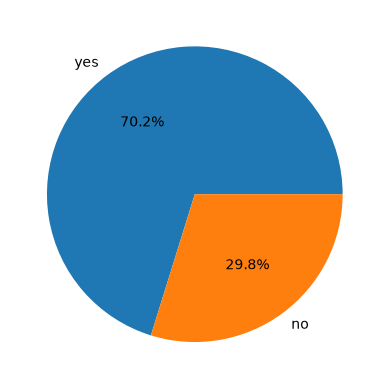

In [15]:
plt.pie( loan_app ,labels = ["yes" , "no"], autopct = "%1.1f%%" )

In [16]:
df.columns

Index(['Applicant_ID', 'Applicant_Income', 'Coapplicant_Income',
       'Employment_Status', 'Age', 'Marital_Status', 'Dependents',
       'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings',
       'Collateral_Value', 'Loan_Amount', 'Loan_Term', 'Loan_Purpose',
       'Property_Area', 'Education_Level', 'Gender', 'Employer_Category',
       'Loan_Approved'],
      dtype='str')

In [22]:
gender_value_counts = df['Gender'].value_counts()

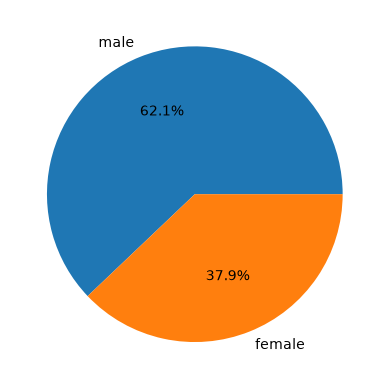

In [23]:
plt.pie(gender_value_counts , labels = ["male" , "female"] , autopct = "%1.1f%%")

In [24]:
Education_Level_value_counts= df['Education_Level'].value_counts()

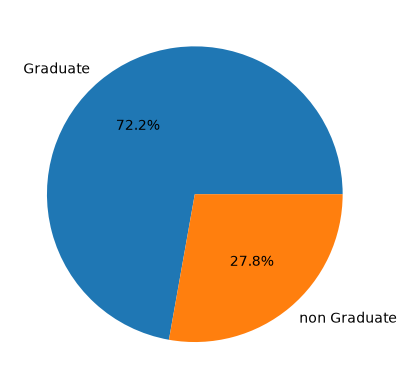

In [33]:
plt.pie(Education_Level_value_counts , labels = ["Graduate" , "non Graduate"], autopct = "%1.1f%%" )

In [34]:
Loan_Purposel_value_counts= df['Loan_Purpose'].value_counts()

In [35]:
Loan_Purposel_value_counts

Loan_Purpose
Business     252
Car          199
Home         190
Education    181
Personal     178
Name: count, dtype: int64

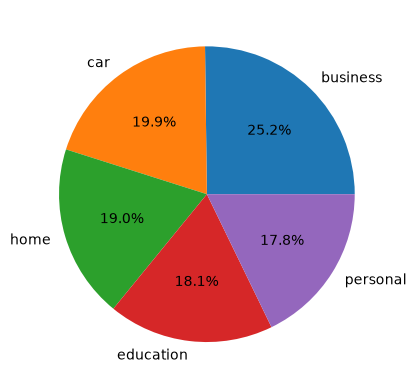

In [37]:
plt.pie(Loan_Purposel_value_counts , labels = ['business' , 'car' , 'home', 'education' , 'personal'] , autopct = "%1.1f%%")

In [41]:
df.columns

Index(['Applicant_ID', 'Applicant_Income', 'Coapplicant_Income',
       'Employment_Status', 'Age', 'Marital_Status', 'Dependents',
       'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings',
       'Collateral_Value', 'Loan_Amount', 'Loan_Term', 'Loan_Purpose',
       'Property_Area', 'Education_Level', 'Gender', 'Employer_Category',
       'Loan_Approved'],
      dtype='str')

<Axes: >

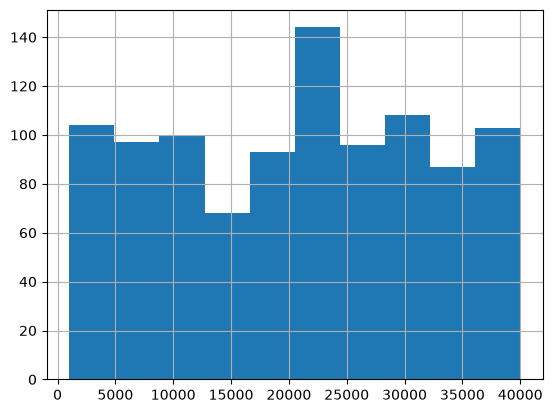

In [43]:
df["Loan_Amount"].hist()

<Axes: >

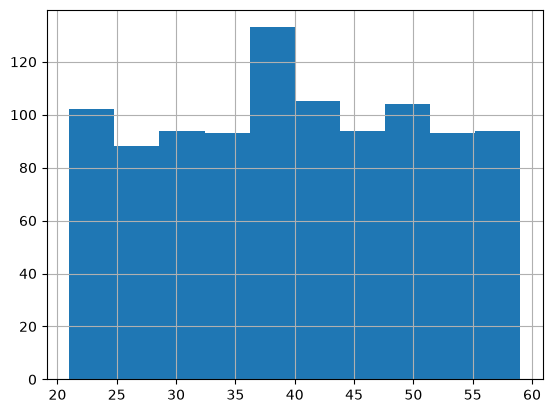

In [45]:
df["Age"].hist()

<Axes: xlabel='Age', ylabel='Credit_Score'>

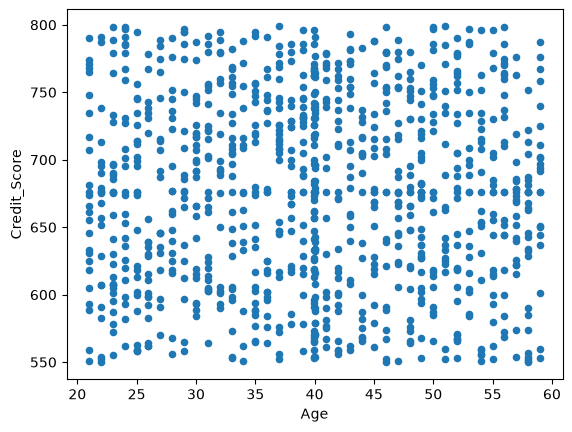

In [47]:
df.plot(kind = 'scatter' , x = "Age" , y = 'Credit_Score')

In [ ]:
sns.boxplot(
    
)